In [1]:
import numpy as np 
import torch as tt 
import torch.nn as nn 

Entropy and Cross-entropy 

In [2]:
p = .24 


H = - (p * np.log(p) + (1-p) * np.log(1-p) ) 
#                -> models prediction     1-p -> for binary prediction 
print(H)

0.5510799280869728


Cross entropy 

In [3]:
p = [1,0] # -> real lables 
q = [.5, .5] # -> model prediction 


H = 0 
for i in range(len(p)) : 
    H -= p[i] * np.log(q[i]) 

print(H)

0.6931471805599453


In [4]:
q_tensort = tt.Tensor(q) 
p_tensor = tt.Tensor(p) 

nn.functional.binary_cross_entropy(q_tensort,p_tensor)

tensor(0.6931)

# Variance 

In [5]:
# min & max 

t1 = tt.rand(4,5) 
t1

tensor([[0.9346, 0.9581, 0.2495, 0.8782, 0.6755],
        [0.3803, 0.0830, 0.2076, 0.8956, 0.0142],
        [0.7964, 0.3413, 0.8878, 0.9975, 0.6010],
        [0.7079, 0.6980, 0.8772, 0.6754, 0.8241]])

In [6]:
t1.max(dim=0) # colume 

# dim=1     -> row

torch.return_types.max(
values=tensor([0.9346, 0.9581, 0.8878, 0.9975, 0.8241]),
indices=tensor([0, 0, 2, 2, 3]))

In [7]:
t1[:, 1]

tensor([0.9581, 0.0830, 0.3413, 0.6980])

In [8]:
t1[1:-1, 1:-1]

tensor([[0.0830, 0.2076, 0.8956],
        [0.3413, 0.8878, 0.9975]])

In [9]:
# always rows(0) first and columes(1) second (2,4) except for dim (1,0)

In [10]:
a = tt.Tensor([3,2,2,2,1]) 
b = tt.Tensor([14,4,-5,-5,2])

In [11]:
print(tt.mean(a)) 
print(tt.mean(b))

tensor(2.)
tensor(2.)


In [12]:
print(tt.var(a))

tensor(0.5000)


In [13]:
print(tt.var(b))

tensor(61.5000)


### derivative 

In [14]:
def f(x) : 
    return x ** 3

def df(x) : 
    return 3 * x ** 2  


In [15]:
x = tt.linspace(-1,1,50)
x

tensor([-1.0000, -0.9592, -0.9184, -0.8776, -0.8367, -0.7959, -0.7551, -0.7143,
        -0.6735, -0.6327, -0.5918, -0.5510, -0.5102, -0.4694, -0.4286, -0.3878,
        -0.3469, -0.3061, -0.2653, -0.2245, -0.1837, -0.1429, -0.1020, -0.0612,
        -0.0204,  0.0204,  0.0612,  0.1020,  0.1429,  0.1837,  0.2245,  0.2653,
         0.3061,  0.3469,  0.3878,  0.4286,  0.4694,  0.5102,  0.5510,  0.5918,
         0.6327,  0.6735,  0.7143,  0.7551,  0.7959,  0.8367,  0.8776,  0.9184,
         0.9592,  1.0000])

In [16]:
fx = f(x) 
dx = df(x) 

In [17]:
import matplotlib.pyplot as plt 

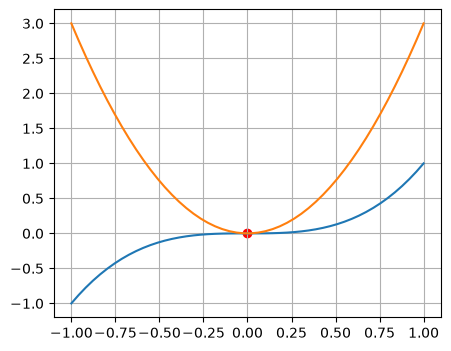

In [18]:
plt.figure(figsize=(5,4))   
plt.plot(x,fx)   
plt.plot(x,dx)   

plt.grid()
plt.scatter(0,0, c='red')
plt.show()   

In [19]:
# minima :    ->    df < 0 (left) &  df > 0 (right) 

# maxima :    ->    df > 0 (left) & df < 0 (right) 

# df = 0 


Gradiant decend 

In [20]:
localmin = np.random.choice(x, 1) 
localmin 

array([0.42857143], dtype=float32)

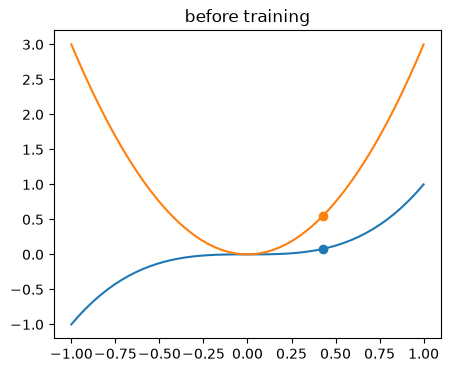

In [21]:
plt.figure(figsize=(5,4)) 
plt.plot(x, fx) 
plt.plot(x, dx) 

plt.title("before training")
plt.scatter(localmin, f(localmin))
plt.scatter(localmin, df(localmin))


In [22]:
lr = .01 

training_epoch = 100 

for i in range(training_epoch) : 
    grad = df(localmin) 
    localmin = localmin - lr * grad 

print(localmin) 
print(f"learning rate : {lr}") 
print(f"number of training : {training_epoch}")

[0.18662344]
learning rate : 0.01
number of training : 100


In [23]:
type(localmin)

numpy.ndarray

Text(0.5, 1.0, 'after training')

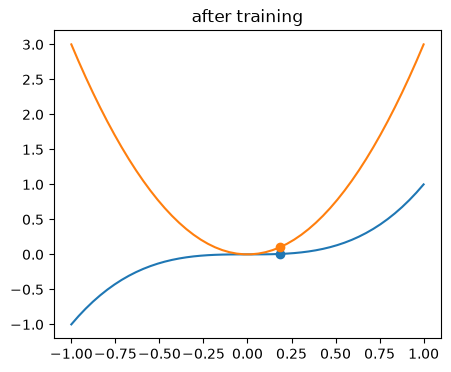

In [24]:
plt.figure(figsize=(5,4)) 
plt.plot(x, fx) 
plt.plot(x, dx) 

plt.scatter(localmin, f(localmin))
plt.scatter(localmin, df(localmin))
plt.title("after training")

### Track localmin at random starting points 

In [25]:
def f(x) : 
    return np.sin(x) + 0.3 * np.sin(3*x) + 0.1 * x 

def df(x) : 
    return np.cos(x) + .9 * np.cos(3*x) + .1 

In [26]:
x = np.linspace(-10,10,1000)

In [27]:
fx = f(x) 
dx = df(x) 

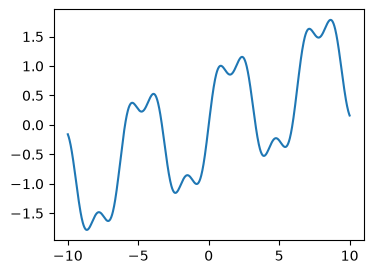

In [28]:
plt.figure(figsize=(4,3)) 
plt.plot(x, fx)
plt.show() 

In [29]:
localmin = np.random.choice(x, 1) 
localmin

array([3.91391391])

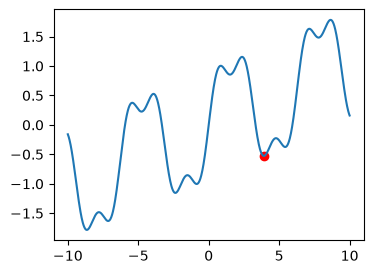

In [30]:
plt.figure(figsize=(4,3)) 
plt.plot(x, fx)
plt.scatter(localmin, f(localmin), c='red')
plt.show() 

In [31]:
localmins = np.zeros((5, training_epoch)) 
localmins.shape

(5, 100)

### grad = derv(localmin ) : 

مثلاً در \(x=-3\):
###    اگر شیب خط منفی باشد اگر به سمت چپ بریم مقدار کمتر میشود پس باید به سمت راست حرکت کنیم چون که باید مشتق برابر با 0 شود مقادیر 0 برای مینیموم هست 


###    اگر هم که شیب مثبت باشد باید به سمت چپ حرکت کنیم که کمتر شود و به 0 نزدیک تر شویم 

In [32]:

# Parameters 

lr = .01 
training_epoch = 100

In [33]:
for i in localmins : 

    # random starting point 
    localmin = np.random.choice(x, 1) 

    for d in range(training_epoch) : 
        
        grad = df(localmin) 
        
        # 
        localmin -= lr * grad 
        i[d] = localmin[0]
        


In [34]:
localmins

array([[-9.72595914, -9.71183979, -9.69738515, -9.68260012, -9.6674912 ,
        -9.65206658, -9.63633619, -9.62031176, -9.60400688, -9.587437  ,
        -9.57061945, -9.55357338, -9.53631972, -9.51888106, -9.50128157,
        -9.48354682, -9.4657036 , -9.44777972, -9.42980379, -9.41180494,
        -9.39381259, -9.37585619, -9.35796491, -9.34016741, -9.32249157,
        -9.30496425, -9.2876111 , -9.27045633, -9.25352258, -9.23683077,
        -9.2204    , -9.20424748, -9.18838853, -9.1728365 , -9.15760284,
        -9.14269713, -9.12812713, -9.11389888, -9.10001677, -9.08648365,
        -9.07330096, -9.0604688 , -9.04798611, -9.03585073, -9.02405955,
        -9.01260861, -9.0014932 , -8.99070797, -8.98024703, -8.97010404,
        -8.96027226, -8.95074466, -8.94151397, -8.93257276, -8.92391346,
        -8.91552843, -8.90741001, -8.89955055, -8.89194243, -8.88457808,
        -8.87745007, -8.87055103, -8.86387376, -8.85741116, -8.85115631,
        -8.84510245, -8.83924299, -8.83357149, -8.8

In [35]:
f

<function __main__.f(x)>

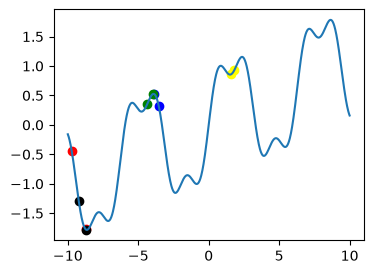

In [36]:
plt.figure(figsize=(4,3)) 
plt.plot(x, fx)

colored = ["red", "black", "blue", "green", "yellow"]
for i in range(len(localmins)) : 
    plt.scatter(localmins[i][0], f(localmins[i][0]), c=colored[i])
    plt.scatter(localmins[i][-1], f(localmins[i][-1]), c=colored[i])

plt.show() 

In [37]:
localmins[0][-1]

np.float64(-8.721675160217801)

0.01